<a href="https://colab.research.google.com/github/HashimK1411/MSc_Project/blob/main/01_RF_B_CICIDS2017_Baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import sys
import tensorflow as tf

print("Python version:", sys.version)
print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

Python version: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
TensorFlow version: 2.19.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
!pip install -q tensorflow_decision_forests==1.12.0 imbalanced-learn pyarrow

import os
import glob
import time
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
import tensorflow_decision_forests as tfdf

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    classification_report,
    ConfusionMatrixDisplay
)

print("TensorFlow:", tf.__version__)
print("TF-DF:", tfdf.__version__)

TensorFlow: 2.19.0
TF-DF: 1.12.0


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
PROJECT_DIR = "/content/drive/MyDrive/MSc_Project"

RAW_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "CICIDS2017",
    "raw"
)

PROCESSED_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "CICIDS2017",
    "processed"
)

RESULTS_DIR = os.path.join(
    PROJECT_DIR,
    "results",
    "RF_B_CIC"
)

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models",
    "RF_B_CIC"
)

os.makedirs(PROCESSED_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

TRAIN_PATH = os.path.join(
    PROCESSED_DIR,
    "cicids2017_train.parquet"
)

VAL_PATH = os.path.join(
    PROCESSED_DIR,
    "cicids2017_validation.parquet"
)

TEST_PATH = os.path.join(
    PROCESSED_DIR,
    "cicids2017_test.parquet"
)

print("RAW_DIR:", RAW_DIR)
print("PROCESSED_DIR:", PROCESSED_DIR)
print("RESULTS_DIR:", RESULTS_DIR)
print("MODEL_DIR:", MODEL_DIR)

RAW_DIR: /content/drive/MyDrive/MSc_Project/data/CICIDS2017/raw
PROCESSED_DIR: /content/drive/MyDrive/MSc_Project/data/CICIDS2017/processed
RESULTS_DIR: /content/drive/MyDrive/MSc_Project/results/RF_B_CIC
MODEL_DIR: /content/drive/MyDrive/MSc_Project/models/RF_B_CIC


In [ ]:
csv_files = sorted(
    glob.glob(
        os.path.join(RAW_DIR, "*.csv")
    )
)

print("Number of CSV files found:", len(csv_files))

for file in csv_files:
    print(os.path.basename(file))

Number of CSV files found: 8
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Friday-WorkingHours-Morning.pcap_ISCX.csv
Monday-WorkingHours.pcap_ISCX.csv
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Tuesday-WorkingHours.pcap_ISCX.csv
Wednesday-workingHours.pcap_ISCX.csv


In [ ]:
frames = []

for file in csv_files:

    print(
        "Loading:",
        os.path.basename(file)
    )

    temp_df = pd.read_csv(
        file,
        low_memory=False
    )

    temp_df.columns = (
        temp_df.columns
        .str.strip()
    )

    temp_df["source_file"] = (
        os.path.basename(file)
    )

    frames.append(temp_df)

df = pd.concat(
    frames,
    ignore_index=True
)

print("\nCombined dataset shape:")
print(df.shape)

print("\nFirst five rows:")
display(df.head())

Loading: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Loading: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Loading: Friday-WorkingHours-Morning.pcap_ISCX.csv
Loading: Monday-WorkingHours.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Loading: Tuesday-WorkingHours.pcap_ISCX.csv
Loading: Wednesday-workingHours.pcap_ISCX.csv

Combined dataset shape:
(2830743, 80)

First five rows:


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,source_file
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv


In [ ]:
LABEL_COL = "Label"

# -------------------------------------------------
# 1. Verify the label exists
# -------------------------------------------------

if LABEL_COL not in df.columns:
    raise ValueError(
        f"Label column '{LABEL_COL}' was not found."
    )

# -------------------------------------------------
# 2. Clean labels
# -------------------------------------------------

df[LABEL_COL] = (
    df[LABEL_COL]
    .astype(str)
    .str.strip()
)

df[LABEL_COL] = (
    df[LABEL_COL]
    .str.replace(
        "Web Attack � ",
        "Web Attack - ",
        regex=False
    )
    .str.replace(
        "Web Attack - Sql Injection",
        "Web Attack - SQL Injection",
        regex=False
    )
)

# -------------------------------------------------
# 3. Remove identifier/leakage-type columns
# -------------------------------------------------

identifier_columns = [
    "Flow ID",
    "Source IP",
    "Destination IP",
    "Timestamp"
]

existing_identifiers = [
    col
    for col in identifier_columns
    if col in df.columns
]

print(
    "Identifier columns removed:",
    existing_identifiers
)

df = df.drop(
    columns=existing_identifiers,
    errors="ignore"
)

# -------------------------------------------------
# 4. Convert features to numeric
# -------------------------------------------------

feature_columns = [
    col
    for col in df.columns
    if col not in [
        LABEL_COL,
        "source_file"
    ]
]

for col in feature_columns:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce",
        downcast="float"
    )

# -------------------------------------------------
# 5. Replace Infinity values
# -------------------------------------------------

df.replace(
    [np.inf, -np.inf],
    np.nan,
    inplace=True
)

# -------------------------------------------------
# 6. Remove rows containing invalid values
# -------------------------------------------------

rows_before = len(df)

df = (
    df
    .dropna()
    .reset_index(drop=True)
)

rows_after = len(df)

print("\nRows before invalid-value cleaning:",
      rows_before)

print("Rows after cleaning:",
      rows_after)

print("Rows removed:",
      rows_before - rows_after)

# -------------------------------------------------
# 7. Verify labels
# -------------------------------------------------

print("\nCleaned labels:")

for label in sorted(
    df[LABEL_COL].unique()
):
    print(label)

Identifier columns removed: []

Rows before invalid-value cleaning: 2830743
Rows after cleaning: 2827876
Rows removed: 2867

Cleaned labels:
BENIGN
Bot
DDoS
DoS GoldenEye
DoS Hulk
DoS Slowhttptest
DoS slowloris
FTP-Patator
Heartbleed
Infiltration
PortScan
SSH-Patator
Web Attack - Brute Force
Web Attack - SQL Injection
Web Attack - XSS


In [ ]:
rows_before = len(df)

duplicate_columns = [
    col
    for col in df.columns
    if col != "source_file"
]

df = (
    df
    .drop_duplicates(
        subset=duplicate_columns
    )
    .reset_index(drop=True)
)

rows_after = len(df)

print(
    "Rows before duplicate removal:",
    rows_before
)

print(
    "Rows after duplicate removal:",
    rows_after
)

print(
    "Exact duplicates removed:",
    rows_before - rows_after
)

# -------------------------------------------------
# Class distribution
# -------------------------------------------------

class_counts = (
    df[LABEL_COL]
    .value_counts()
)

class_percentages = (
    df[LABEL_COL]
    .value_counts(normalize=True)
    .mul(100)
)

class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages
})

print("\nClass distribution:")
display(class_summary)

class_summary.to_csv(
    os.path.join(
        RESULTS_DIR,
        "cicids2017_class_distribution.csv"
    )
)

Rows before duplicate removal: 2827876
Rows after duplicate removal: 2520792
Exact duplicates removed: 307084

Class distribution:


,Count,Percentage
Label,,
BENIGN,2095051,83.110824
DoS Hulk,172846,6.856813
DDoS,128014,5.078325
PortScan,90694,3.597838
DoS GoldenEye,10286,0.408046
FTP-Patator,5931,0.235283
DoS slowloris,5385,0.213623
DoS Slowhttptest,5228,0.207395
SSH-Patator,3219,0.127698


In [ ]:
model_df = (
    df
    .drop(
        columns=["source_file"],
        errors="ignore"
    )
    .copy()
)

print(
    "Model dataset shape:",
    model_df.shape
)

print(
    "Number of features:",
    model_df.shape[1] - 1
)

print(
    "Number of classes:",
    model_df[LABEL_COL].nunique()
)

print("\nFinal labels:")

for label in sorted(
    model_df[LABEL_COL].unique()
):
    print(label)

Model dataset shape: (2520792, 79)
Number of features: 78
Number of classes: 15

Final labels:
BENIGN
Bot
DDoS
DoS GoldenEye
DoS Hulk
DoS Slowhttptest
DoS slowloris
FTP-Patator
Heartbleed
Infiltration
PortScan
SSH-Patator
Web Attack - Brute Force
Web Attack - SQL Injection
Web Attack - XSS


In [ ]:
SEED = 42

train_df, temp_df = train_test_split(
    model_df,
    test_size=0.30,
    random_state=SEED,
    stratify=model_df[LABEL_COL]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df[LABEL_COL]
)

print(
    "Training:",
    train_df.shape
)

print(
    "Validation:",
    val_df.shape
)

print(
    "Testing:",
    test_df.shape
)

print("\nTRAIN DISTRIBUTION")
print(
    train_df[LABEL_COL]
    .value_counts(normalize=True)
)

print("\nVALIDATION DISTRIBUTION")
print(
    val_df[LABEL_COL]
    .value_counts(normalize=True)
)

print("\nTEST DISTRIBUTION")
print(
    test_df[LABEL_COL]
    .value_counts(normalize=True)
)

Training: (1764554, 79)
Validation: (378119, 79)
Testing: (378119, 79)

TRAIN DISTRIBUTION
Label
BENIGN                        0.831108
DoS Hulk                      0.068568
DDoS                          0.050783
PortScan                      0.035978
DoS GoldenEye                 0.004080
FTP-Patator                   0.002353
DoS slowloris                 0.002136
DoS Slowhttptest              0.002074
SSH-Patator                   0.001277
Bot                           0.000773
Web Attack - Brute Force      0.000583
Web Attack - XSS              0.000258
Infiltration                  0.000014
Web Attack - SQL Injection    0.000009
Heartbleed                    0.000005
Name: proportion, dtype: float64

VALIDATION DISTRIBUTION
Label
BENIGN                        0.831109
DoS Hulk                      0.068568
DDoS                          0.050783
PortScan                      0.035978
DoS GoldenEye                 0.004081
FTP-Patator                   0.002351
DoS slowloris       

In [ ]:
print("Saving training partition...")

train_df.to_parquet(
    TRAIN_PATH,
    index=False
)

print("Saving validation partition...")

val_df.to_parquet(
    VAL_PATH,
    index=False
)

print("Saving test partition...")

test_df.to_parquet(
    TEST_PATH,
    index=False
)

print("\nSave complete.")

print(
    "Train exists:",
    os.path.exists(TRAIN_PATH)
)

print(
    "Validation exists:",
    os.path.exists(VAL_PATH)
)

print(
    "Test exists:",
    os.path.exists(TEST_PATH)
)

Saving training partition...
Saving validation partition...
Saving test partition...

Save complete.
Train exists: True
Validation exists: True
Test exists: True


In [ ]:
# Cell 12 — Reload and verify the saved partitions

LABEL_COL = "Label"

train_df = pd.read_parquet(
    TRAIN_PATH
)

val_df = pd.read_parquet(
    VAL_PATH
)

test_df = pd.read_parquet(
    TEST_PATH
)

print(
    "Training reloaded:",
    train_df.shape
)

print(
    "Validation reloaded:",
    val_df.shape
)

print(
    "Testing reloaded:",
    test_df.shape
)

# Verify label column
if LABEL_COL not in train_df.columns:
    raise ValueError(
        f"'{LABEL_COL}' column not found in training data."
    )

print("\nClasses:")

for label in sorted(
    train_df[LABEL_COL].unique()
):
    print(label)

Training reloaded: (1764554, 79)
Validation reloaded: (378119, 79)
Testing reloaded: (378119, 79)

Classes:
BENIGN
Bot
DDoS
DoS GoldenEye
DoS Hulk
DoS Slowhttptest
DoS slowloris
FTP-Patator
Heartbleed
Infiltration
PortScan
SSH-Patator
Web Attack - Brute Force
Web Attack - SQL Injection
Web Attack - XSS


In [ ]:
train_ds = (
    tfdf.keras
    .pd_dataframe_to_tf_dataset(
        train_df,
        label=LABEL_COL,
        task=tfdf.keras.Task.CLASSIFICATION
    )
)

val_ds = (
    tfdf.keras
    .pd_dataframe_to_tf_dataset(
        val_df,
        label=LABEL_COL,
        task=tfdf.keras.Task.CLASSIFICATION
    )
)

test_ds = (
    tfdf.keras
    .pd_dataframe_to_tf_dataset(
        test_df,
        label=LABEL_COL,
        task=tfdf.keras.Task.CLASSIFICATION
    )
)

print(
    "TensorFlow Decision Forest datasets created successfully."
)

TensorFlow Decision Forest datasets created successfully.


In [ ]:
rf_b_cic = tfdf.keras.RandomForestModel(

    # 100 decision trees
    num_trees=100,

    # Unlimited tree depth
    max_depth=-1,

    # Minimum observations per node
    min_examples=1,

    # Classical Random Forest feature sampling
    num_candidate_attributes=0,

    # Bootstrap sampling
    bootstrap_training_dataset=True,
    bootstrap_size_ratio=1.0,
    sampling_with_replacement=True,

    # Reproducibility
    random_seed=42,

    # Out-of-bag monitoring
    compute_oob_performances=True,

    verbose=2
)

rf_b_cic.compile(
    metrics=["accuracy"]
)

print("RF-B-CIC configured.")

Use 8 thread(s) for training
Use /tmp/tmp0llrh3mv as temporary training directory
RF-B-CIC configured.


In [ ]:
start_time = time.time()

rf_b_cic.fit(
    train_ds
)

training_time = (
    time.time() - start_time
)

print(
    "\nTraining completed."
)

print(
    f"Training time: "
    f"{training_time:.2f} seconds"
)

Reading training dataset...
Training tensor examples:
Features: {'Destination_Port': <tf.Tensor 'data:0' shape=(None,) dtype=float32>, 'Flow_Duration': <tf.Tensor 'data_1:0' shape=(None,) dtype=float64>, 'Total_Fwd_Packets': <tf.Tensor 'data_2:0' shape=(None,) dtype=float32>, 'Total_Backward_Packets': <tf.Tensor 'data_3:0' shape=(None,) dtype=float32>, 'Total_Length_of_Fwd_Packets': <tf.Tensor 'data_4:0' shape=(None,) dtype=float32>, 'Total_Length_of_Bwd_Packets': <tf.Tensor 'data_5:0' shape=(None,) dtype=float64>, 'Fwd_Packet_Length_Max': <tf.Tensor 'data_6:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Min': <tf.Tensor 'data_7:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Mean': <tf.Tensor 'data_8:0' shape=(None,) dtype=float32>, 'Fwd_Packet_Length_Std': <tf.Tensor 'data_9:0' shape=(None,) dtype=float32>, 'Bwd_Packet_Length_Max': <tf.Tensor 'data_10:0' shape=(None,) dtype=float32>, 'Bwd_Packet_Length_Min': <tf.Tensor 'data_11:0' shape=(None,) dtype=float32>, 'Bwd_Packet_Le

I0000 00:00:1790264696.308812     243 kernel.cc:782] Start Yggdrasil model training
I0000 00:00:1790264696.309135     243 kernel.cc:783] Collect training examples
I0000 00:00:1790264696.309150     243 kernel.cc:795] Dataspec guide:
column_guides {
  column_name_pattern: "^__LABEL$"
  type: CATEGORICAL
  categorial {
    min_vocab_frequency: 0
    max_vocab_count: -1
  }
}
default_column_guide {
  categorial {
    max_vocab_count: 2000
  }
  discretized_numerical {
    maximum_num_bins: 255
  }
}
ignore_columns_without_guides: false
detect_numerical_as_discretized_numerical: false

I0000 00:00:1790264696.309840     243 kernel.cc:401] Number of batches: 1765
I0000 00:00:1790264696.309859     243 kernel.cc:402] Number of examples: 1764554
I0000 00:00:1790264697.287923     243 kernel.cc:802] Training dataset:
Number of records: 1764554
Number of columns: 79

Number of columns by type:
	NUMERICAL: 78 (98.7342%)
	CATEGORICAL: 1 (1.26582%)

Columns:

NUMERICAL: 78 (98.7342%)
	0: "ACK_Flag_Cou

Model trained in 0:03:49.160642
Compiling model...
Model compiled.

Training completed.
Training time: 302.87 seconds


In [ ]:
# Cell 16 — Inspect and evaluate the trained RF-B-CIC model

inspector = rf_b_cic.make_inspector()

print(
    "Model type:",
    inspector.model_type()
)

print(
    "Number of trees:",
    inspector.num_trees()
)

print(
    "Classes:",
    inspector.label_classes()
)

print("\nOut-of-bag evaluation:")

print(
    inspector.evaluation()
)

print("\nFinal test evaluation:")

test_results = rf_b_cic.evaluate(
    test_ds,
    return_dict=True
)

print(test_results)

Model type: RANDOM_FOREST
Number of trees: 100
Classes: None

Out-of-bag evaluation:
Evaluation(num_examples=1764554, accuracy=0.9985191725501175, loss=0.015828377678704045, rmse=None, ndcg=None, aucs=None, auuc=None, qini=None)

Final test evaluation:
379/379 [==============================] - 15s 39ms/step - loss: 0.0000e+00 - accuracy: 0.9986
{'loss': 0.0, 'accuracy': 0.998606264591217}


In [ ]:
# Cell 17 — Generate predictions and calculate baseline metrics

# -------------------------------------------------
# 1. Recover the TF-DF class order
# -------------------------------------------------
# pd_dataframe_to_tf_dataset() integerises string
# classification labels in lexicographical order.

class_names = sorted(
    train_df[LABEL_COL]
    .astype(str)
    .unique()
    .tolist()
)

print("Class order used for prediction:")

for idx, label in enumerate(class_names):
    print(idx, "->", label)

print("\nNumber of classes:", len(class_names))


# -------------------------------------------------
# 2. Generate prediction probabilities
# -------------------------------------------------

pred_probabilities = rf_b_cic.predict(
    test_ds,
    verbose=0
)

print(
    "\nPrediction matrix shape:",
    pred_probabilities.shape
)

# Safety check
if pred_probabilities.shape[1] != len(class_names):
    raise ValueError(
        "Prediction output does not match "
        "the number of known classes."
    )


# -------------------------------------------------
# 3. Convert probabilities to predicted class IDs
# -------------------------------------------------

y_pred_ids = np.argmax(
    pred_probabilities,
    axis=1
)


# -------------------------------------------------
# 4. Encode the true labels using the SAME
#    lexicographical class ordering
# -------------------------------------------------

label_to_id = {
    label: idx
    for idx, label in enumerate(class_names)
}

y_true_ids = (
    test_df[LABEL_COL]
    .astype(str)
    .map(label_to_id)
    .to_numpy()
)

# Safety check
if pd.isna(y_true_ids).any():
    raise ValueError(
        "An unknown label was found in the test set."
    )


# -------------------------------------------------
# 5. Convert IDs back to readable labels
# -------------------------------------------------

y_pred = np.array(class_names)[y_pred_ids]

y_true = (
    test_df[LABEL_COL]
    .astype(str)
    .to_numpy()
)


# -------------------------------------------------
# 6. Calculate evaluation metrics
# -------------------------------------------------

accuracy = accuracy_score(
    y_true,
    y_pred
)

macro_precision = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

weighted_f1 = f1_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

balanced_accuracy = balanced_accuracy_score(
    y_true,
    y_pred
)

mcc = matthews_corrcoef(
    y_true,
    y_pred
)


# -------------------------------------------------
# 7. Create baseline result table
# -------------------------------------------------

baseline_metrics = {
    "Model": "RF-B-CIC",
    "Accuracy": accuracy,
    "Macro Precision": macro_precision,
    "Macro Recall": macro_recall,
    "Macro F1": macro_f1,
    "Weighted F1": weighted_f1,
    "Balanced Accuracy": balanced_accuracy,
    "MCC": mcc,
    "Training Time Seconds": training_time
}

metrics_df = pd.DataFrame(
    [baseline_metrics]
)

print("\nRF-B-CIC Test Metrics:")
display(metrics_df)

Class order used for prediction:
0 -> BENIGN
1 -> Bot
2 -> DDoS
3 -> DoS GoldenEye
4 -> DoS Hulk
5 -> DoS Slowhttptest
6 -> DoS slowloris
7 -> FTP-Patator
8 -> Heartbleed
9 -> Infiltration
10 -> PortScan
11 -> SSH-Patator
12 -> Web Attack - Brute Force
13 -> Web Attack - SQL Injection
14 -> Web Attack - XSS

Number of classes: 15

Prediction matrix shape: (378119, 15)

RF-B-CIC Test Metrics:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Balanced Accuracy,MCC,Training Time Seconds
0,RF-B-CIC,0.998606,0.935485,0.879297,0.893851,0.99857,0.879297,0.995364,302.872033


RF-B-CIC Per-Class Classification Report:


,precision,recall,f1-score,support
BENIGN,0.999335,0.999373,0.999354,314258.000000
Bot,0.879845,0.777397,0.825455,292.000000
DDoS,0.999948,0.999896,0.999922,19202.000000
DoS GoldenEye,0.999347,0.992223,0.995772,1543.000000
DoS Hulk,0.998650,0.998611,0.998631,25927.000000
DoS Slowhttptest,0.988608,0.996173,0.992376,784.000000
DoS slowloris,0.995037,0.992574,0.993804,808.000000
FTP-Patator,1.000000,0.996629,0.998312,890.000000
Heartbleed,1.000000,1.000000,1.000000,1.000000
Infiltration,1.000000,1.000000,1.000000,5.000000



Classification report saved to: /content/drive/MyDrive/MSc_Project/results/RF_B_CIC/RF_B_CIC_classification_report.csv


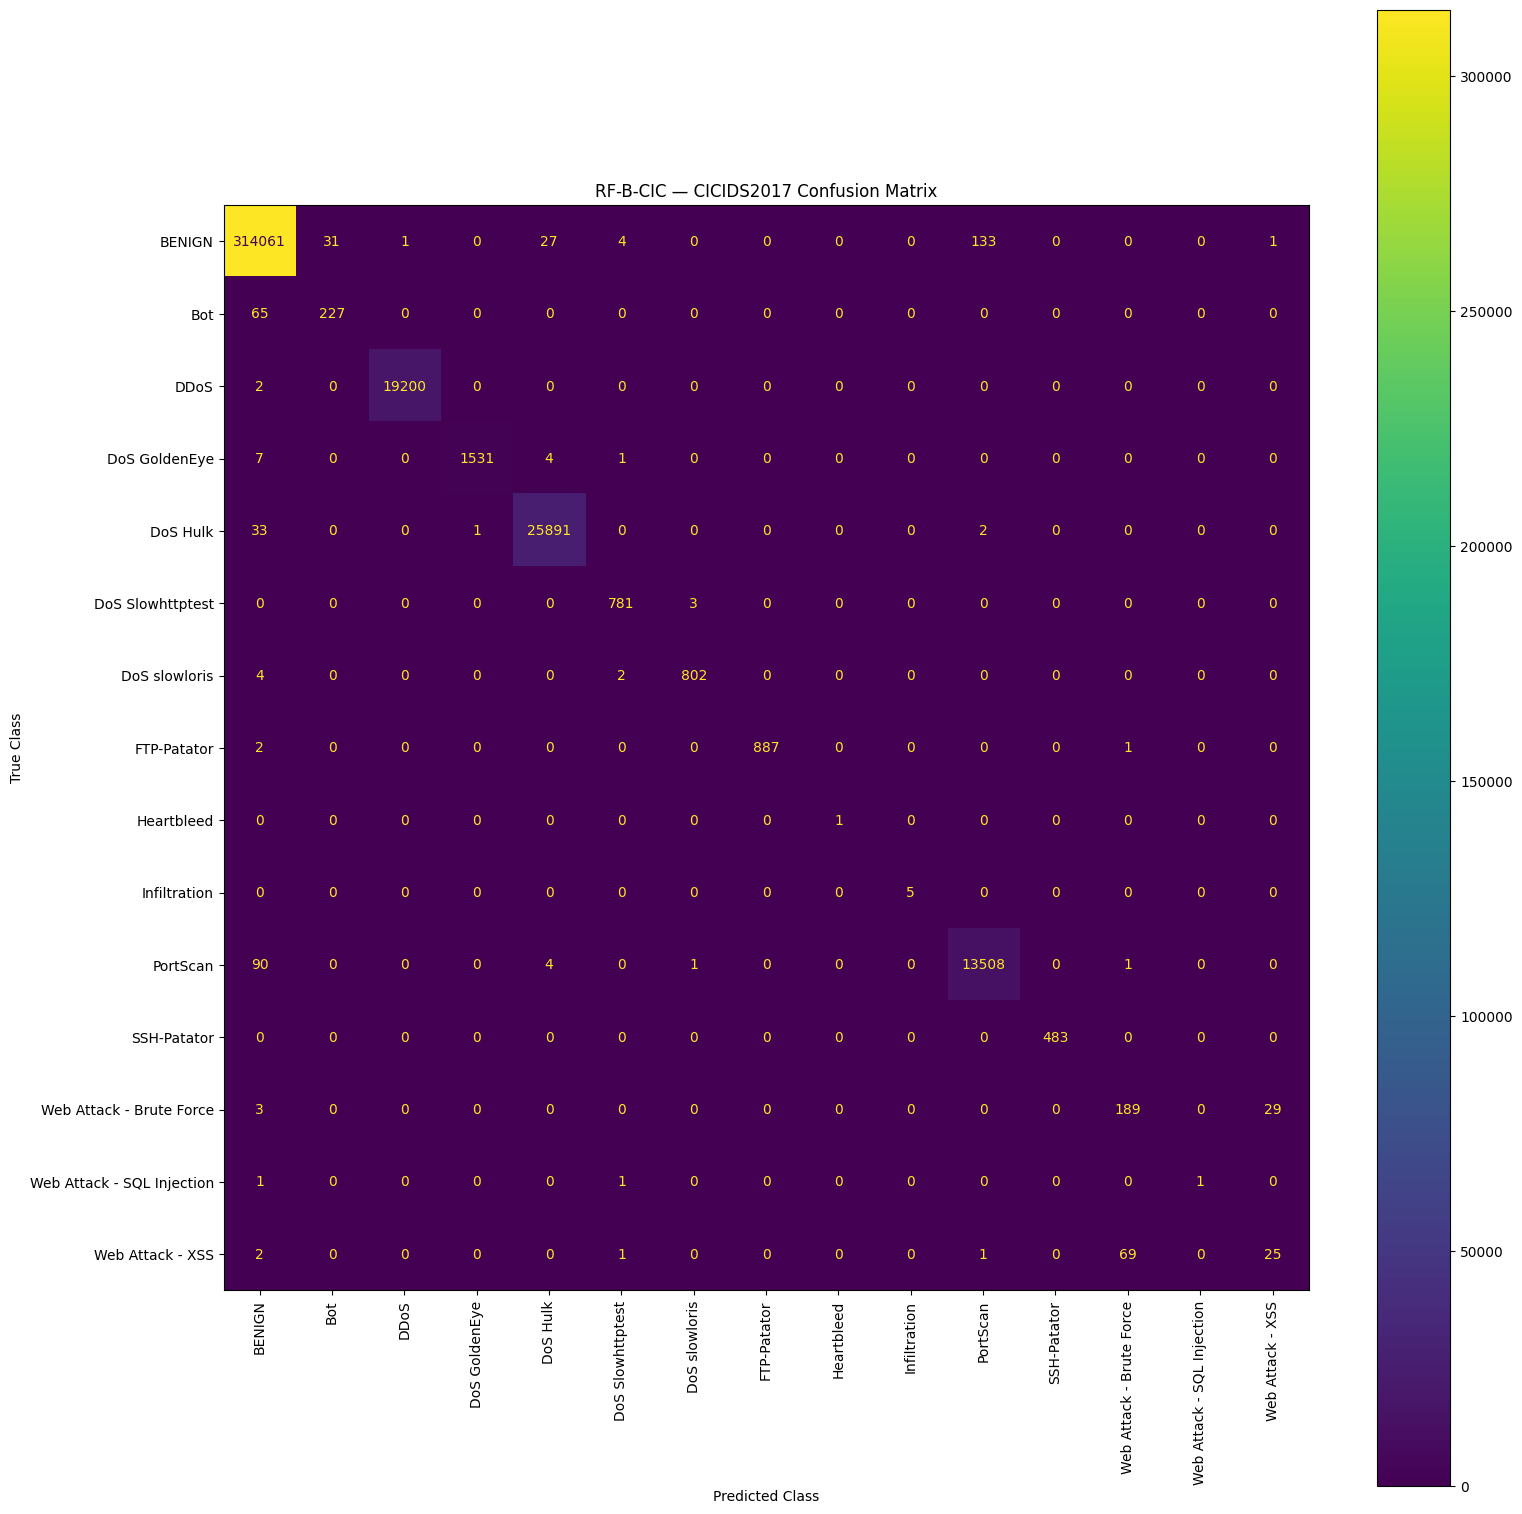


Confusion matrix saved to: /content/drive/MyDrive/MSc_Project/results/RF_B_CIC/RF_B_CIC_confusion_matrix.png


In [ ]:
# Cell 18 — Per-class classification report and confusion matrix

# -------------------------------------------------
# 1. Generate per-class classification report
# -------------------------------------------------

report = classification_report(
    y_true,
    y_pred,
    labels=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(
    report
).transpose()

print("RF-B-CIC Per-Class Classification Report:")

display(report_df)


# -------------------------------------------------
# 2. Save classification report
# -------------------------------------------------

REPORT_PATH = os.path.join(
    RESULTS_DIR,
    "RF_B_CIC_classification_report.csv"
)

report_df.to_csv(
    REPORT_PATH
)

print(
    "\nClassification report saved to:",
    REPORT_PATH
)


# -------------------------------------------------
# 3. Generate confusion matrix
# -------------------------------------------------

fig, ax = plt.subplots(
    figsize=(16, 16)
)

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=class_names,
    display_labels=class_names,
    xticks_rotation=90,
    values_format="d",
    ax=ax
)

plt.title(
    "RF-B-CIC — CICIDS2017 Confusion Matrix"
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "True Class"
)

plt.tight_layout()


# -------------------------------------------------
# 4. Save confusion matrix
# -------------------------------------------------

CONFUSION_MATRIX_PATH = os.path.join(
    RESULTS_DIR,
    "RF_B_CIC_confusion_matrix.png"
)

plt.savefig(
    CONFUSION_MATRIX_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "\nConfusion matrix saved to:",
    CONFUSION_MATRIX_PATH
)

In [ ]:
# Cell 19 — Save RF-B-CIC metrics and model

# -------------------------------------------------
# 1. Save summary metrics
# -------------------------------------------------

METRICS_PATH = os.path.join(
    RESULTS_DIR,
    "RF_B_CIC_metrics.csv"
)

metrics_df.to_csv(
    METRICS_PATH,
    index=False
)

print(
    "Metrics saved to:",
    METRICS_PATH
)


# -------------------------------------------------
# 2. Save model
# -------------------------------------------------

MODEL_SAVE_PATH = os.path.join(
    MODEL_DIR,
    "saved_model"
)

rf_b_cic.save(
    MODEL_SAVE_PATH
)

print(
    "Model saved to:",
    MODEL_SAVE_PATH
)


# -------------------------------------------------
# 3. Confirm all baseline outputs
# -------------------------------------------------

print("\nRF-B-CIC BASELINE OUTPUTS")

print(
    "Metrics file exists:",
    os.path.exists(METRICS_PATH)
)

print(
    "Classification report exists:",
    os.path.exists(
        os.path.join(
            RESULTS_DIR,
            "RF_B_CIC_classification_report.csv"
        )
    )
)

print(
    "Confusion matrix exists:",
    os.path.exists(
        os.path.join(
            RESULTS_DIR,
            "RF_B_CIC_confusion_matrix.png"
        )
    )
)

print(
    "Model directory exists:",
    os.path.exists(MODEL_SAVE_PATH)
)

print("\nRF-B-CIC baseline is now frozen.")

Metrics saved to: /content/drive/MyDrive/MSc_Project/results/RF_B_CIC/RF_B_CIC_metrics.csv


Model saved to: /content/drive/MyDrive/MSc_Project/models/RF_B_CIC/saved_model

RF-B-CIC BASELINE OUTPUTS
Metrics file exists: True
Classification report exists: True
Confusion matrix exists: True
Model directory exists: True

RF-B-CIC baseline is now frozen.
